# DSCI 552 - Homework 4

**Name:** Khushi Patel  
**GitHub Username:** khushigi-a11y  
**USC ID:** 4163615025

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import statsmodels.api as sm
from sklearn.metrics import roc_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize
from sklearn.naive_bayes import MultinomialNB

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) AReM Dataset

In [2]:
data_path = "data/AReM"

#storing every folder
activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]
#creating individual path for each file
for activity in activities:
    folder_path = f"{data_path}/{activity}"
    
    csv_files = []
    
    for file in os.listdir(folder_path):
        if file.endswith(".csv"):
            csv_files.append(file)
    #print how many files r in the list
    print(activity, len(csv_files))

bending1 7
bending2 6
cycling 15
lying 15
sitting 15
standing 15
walking 15


In [3]:
# Stores training and testing paths
train_files = []
test_files = []

for activity in activities:
    folder_path = f"{data_path}/{activity}"
    
    # Getting all the CSV files in the folder
    csv_files = [
        file for file in os.listdir(folder_path)
        if file.endswith(".csv")
    ]
    
    for file in csv_files:
        file_path = f"{folder_path}/{file}"
        
        #assigning the datasets 1 and 2 as the test data
        if activity in ["bending1", "bending2"]:
            if file in ["dataset1.csv", "dataset2.csv"]:
                test_files.append(file_path)
            else:
                train_files.append(file_path)
        
        #assigning datasets 1, 2, and 3 as the test data
        else:
            if file in ["dataset1.csv", "dataset2.csv", "dataset3.csv"]:
                test_files.append(file_path)
            else:
                train_files.append(file_path)

#the number of train and test instances
print("Training instances:", len(train_files))
print("Testing instances:", len(test_files))
print("Total instances:", len(train_files) + len(test_files))

Training instances: 69
Testing instances: 19
Total instances: 88


### (c) Feature Extraction

#### (i) Time-Domain Features

Common time-domain features used in time series classification include:

- Minimum
- Maximum
- Mean
- Median
- Standard deviation
- Variance
- First quartile (Q1)
- Third quartile (Q3)
- Interquartile range (IQR)
- Range
- Root mean square (RMS)
- Skewness
- Kurtosis
- Zero-crossing rate

In [4]:
sample_path = "data/AReM/bending1/dataset1.csv"

sample_df = pd.read_csv(
    sample_path,
    skiprows=4
)

sample_df.head()

,# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


In [5]:
sample_df.shape

(480, 7)

#### (ii) Extraction of Time-Domain Features

For each of the six time series in every instance, the following seven features are extracted: minimum, maximum, mean, median, standard deviation, first quartile, and third quartile.

In [6]:
# Six time series columns from each dataset
time_series_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

# Extracting the features 
def extract_features(file_path):
    
    if "bending2/dataset4.csv" in file_path:
        df = pd.read_csv(
            file_path,
            skiprows=5,
            sep=r"\s+",
            header=None,
            names=[
                "time", "avg_rss12", "var_rss12",
                "avg_rss13", "var_rss13",
                "avg_rss23", "var_rss23"
            ]
        )
    else:
        df = pd.read_csv(
            file_path,
            skiprows=4,
            usecols=range(7)
        )
        
    features = []

    # Going through each of the 6 time series
    for column in time_series_columns:
        series = df[column]

        # Adding the 7 required features
        features.extend([
            series.min(),
            series.max(),
            series.mean(),
            series.median(),
            series.std(),
            series.quantile(0.25),
            series.quantile(0.75)
        ])

    return features

In [7]:
sample_features = extract_features(sample_path)

print("Number of features:", len(sample_features))
print(sample_features)

Number of features: 42
[np.float64(37.25), np.float64(45.0), np.float64(40.62479166666667), np.float64(40.5), np.float64(1.4769669162668115), np.float64(39.25), np.float64(42.0), np.float64(0.0), np.float64(1.3), np.float64(0.35860416666666667), np.float64(0.43), np.float64(0.32260475889665613), np.float64(0.0), np.float64(0.5), np.float64(4.0), np.float64(29.5), np.float64(19.0409375), np.float64(19.25), np.float64(4.462951988916728), np.float64(16.0), np.float64(23.25), np.float64(0.0), np.float64(7.23), np.float64(0.8325416666666666), np.float64(0.5), np.float64(0.9656588815438522), np.float64(0.0), np.float64(1.12), np.float64(27.25), np.float64(38.25), np.float64(34.31129166666666), np.float64(35.0), np.float64(2.188448606924462), np.float64(33.0), np.float64(36.0), np.float64(0.0), np.float64(1.92), np.float64(0.5705833333333333), np.float64(0.43), np.float64(0.5829154940538743), np.float64(0.0), np.float64(1.3)]


In [8]:
feature_names = []

for i in range(1, 7):
    feature_names.extend([
        f"min{i}",
        f"max{i}",
        f"mean{i}",
        f"median{i}",
        f"std{i}",
        f"1st_quart{i}",
        f"3rd_quart{i}"
    ])

print(feature_names)
print("Number of columns:", len(feature_names))

['min1', 'max1', 'mean1', 'median1', 'std1', '1st_quart1', '3rd_quart1', 'min2', 'max2', 'mean2', 'median2', 'std2', '1st_quart2', '3rd_quart2', 'min3', 'max3', 'mean3', 'median3', 'std3', '1st_quart3', '3rd_quart3', 'min4', 'max4', 'mean4', 'median4', 'std4', '1st_quart4', '3rd_quart4', 'min5', 'max5', 'mean5', 'median5', 'std5', '1st_quart5', '3rd_quart5', 'min6', 'max6', 'mean6', 'median6', 'std6', '1st_quart6', '3rd_quart6']
Number of columns: 42


In [9]:
# Combine all training and testing files
all_files = train_files + test_files

all_features = []

# Extracting the features
for file_path in all_files:
    features = extract_features(file_path)
    all_features.append(features)

# Creating a Df with all extracted features
feature_df = pd.DataFrame(
    all_features,
    columns=feature_names
)

feature_df.index = range(1, len(feature_df) + 1)
feature_df.index.name = "Instance"

feature_df

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,0.0,1.50,0.413125,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
2,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,0.0,1.58,0.378083,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
3,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
4,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
5,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,0.0,2.12,0.506583,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
85,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,0.0,3.34,0.486167,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
86,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,0.0,14.50,3.995729,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425


#### (iii) Standard Deviations and 90% Bootstrap Confidence Intervals

In [10]:
feature_std = feature_df.std()

feature_std

min1          9.569975
max1          4.394362
mean1         5.335718
median1       5.440054
std1          1.772153
1st_quart1    6.153590
3rd_quart1    5.138925
min2          0.000000
max2          5.062729
mean2         1.574164
median2       1.412244
std2          0.884105
1st_quart2    0.946386
3rd_quart2    2.125266
min3          2.956462
max3          4.875137
mean3         4.008380
median3       4.036396
std3          0.946710
1st_quart3    4.220658
3rd_quart3    4.171628
min4          0.000000
max4          2.183625
mean4         1.166114
median4       1.145586
std4          0.458242
1st_quart4    0.843620
3rd_quart4    1.552504
min5          6.124001
max5          5.741238
mean5         5.675593
median5       5.813782
std5          1.024898
1st_quart5    6.096465
3rd_quart5    5.531720
min6          0.045838
max6          2.518921
mean6         1.154812
median6       1.086474
std6          0.517617
1st_quart6    0.758584
3rd_quart6    1.523599
dtype: float64

In [11]:
# Function to calculate 90% bootstrap confidence interval
def bootstrap_std_ci(data, n_bootstrap=10000, confidence=0.90):
    
    # Remove missing values
    data = data.dropna()
    
    bootstrap_stds = []

    # Create 10,000 bootstrap samples
    for _ in range(n_bootstrap):
        sample = np.random.choice(
            data,
            size=len(data),
            replace=True
        )

        # Calculate standard deviation of each sample
        bootstrap_stds.append(np.std(sample, ddof=1))

    # Find the lower and upper percentiles
    alpha = 1 - confidence

    lower = np.percentile(
        bootstrap_stds,
        100 * (alpha / 2)
    )

    upper = np.percentile(
        bootstrap_stds,
        100 * (1 - alpha / 2)
    )

    return lower, upper

In [12]:
feature_df.isna().sum()

min1          0
max1          0
mean1         0
median1       0
std1          0
1st_quart1    0
3rd_quart1    0
min2          0
max2          0
mean2         0
median2       0
std2          0
1st_quart2    0
3rd_quart2    0
min3          0
max3          0
mean3         0
median3       0
std3          0
1st_quart3    0
3rd_quart3    0
min4          0
max4          0
mean4         0
median4       0
std4          0
1st_quart4    0
3rd_quart4    0
min5          0
max5          0
mean5         0
median5       0
std5          0
1st_quart5    0
3rd_quart5    0
min6          0
max6          0
mean6         0
median6       0
std6          0
1st_quart6    0
3rd_quart6    0
dtype: int64

In [13]:
feature_df[feature_df.isna().any(axis=1)]

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,


In [14]:

np.random.seed(42)

results = []

# Calculating the standard deviation and CI for all features
for feature in feature_df.columns:
    
    data = feature_df[feature]
    
    # Standard deviation
    std = data.std()
    
    # 90% bootstrap CI
    lower, upper = bootstrap_std_ci(data)
    
    results.append([
        std,
        lower,
        upper
    ])

# table of the results
bootstrap_results = pd.DataFrame(
    results,
    index=feature_df.columns,
    columns=[
        "Standard Deviation",
        "90% CI Lower",
        "90% CI Upper"
    ]
)

bootstrap_results.round(4)

,Standard Deviation,90% CI Lower,90% CI Upper
min1,9.5700,8.2688,10.7696
max1,4.3944,3.3276,5.2853
mean1,5.3357,4.7059,5.8849
median1,5.4401,4.8041,5.9885
std1,1.7722,1.5692,1.9532
1st_quart1,6.1536,5.5635,6.6342
3rd_quart1,5.1389,4.3173,5.8358
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6227,5.4058
mean2,1.5742,1.3965,1.7049


#### (iv) Three Most Important Time-Domain Features

The mean, standard deviation, and maximum are the three most important time-domain features. The mean represents the average signal level, the standard deviation represents how much the signal chnages, and the maximum captures the peak values of the signal.So when they are all put together these features explain different characteristics of the time series that help understand the activities.

# 2. Time Series Classification Part 2: Binary and Multiclass Classification

## (a) Binary Classification Using Logistic Regression

### (i) Scatter Plots for Bending vs. Other Activities

In [15]:
# Features selected in HW3 1(c)(iv)
selected_features = [
    "mean1", "std1", "max1",
    "mean2", "std2", "max2",
    "mean6", "std6", "max6"
]

# Extracting features from training only
train_features = []

for file_path in train_files:
    features = extract_features(file_path)
    train_features.append(features)

# Creating dataframe
train_feature_df = pd.DataFrame(
    train_features,
    columns=feature_names
)

# Keeping only the selected features
train_feature_df = train_feature_df[selected_features]

train_feature_df.head()

,mean1,std1,max1,mean2,std2,max2,mean6,std6,max6
0,43.969125,1.618364,48.00,0.413125,0.263111,1.50,0.555312,0.487826,2.96
1,43.454958,1.386098,48.00,0.378083,0.315566,1.58,0.679646,0.622534,5.26
2,42.179812,3.670666,47.75,0.696042,0.630860,3.00,0.613521,0.524317,2.18
3,41.678063,2.243490,45.75,0.535979,0.405469,2.83,0.383292,0.389164,1.79
4,43.954500,1.558835,47.40,0.426250,0.338690,1.70,0.493292,0.513506,1.79


In [16]:
# Create binary labels
labels = []

for file_path in train_files:
    if "bending1" in file_path or "bending2" in file_path:
        labels.append(1)
    else:
        labels.append(0)

train_feature_df["label"] = labels

train_feature_df.head()

,mean1,std1,max1,mean2,std2,max2,mean6,std6,max6,label
0,43.969125,1.618364,48.00,0.413125,0.263111,1.50,0.555312,0.487826,2.96,1
1,43.454958,1.386098,48.00,0.378083,0.315566,1.58,0.679646,0.622534,5.26,1
2,42.179812,3.670666,47.75,0.696042,0.630860,3.00,0.613521,0.524317,2.18,1
3,41.678063,2.243490,45.75,0.535979,0.405469,2.83,0.383292,0.389164,1.79,1
4,43.954500,1.558835,47.40,0.426250,0.338690,1.70,0.493292,0.513506,1.79,1


In [17]:
train_feature_df["label"].value_counts()

label
0    60
1     9
Name: count, dtype: int64

In [18]:
plot_df = train_feature_df.copy()

plot_df["Activity"] = plot_df["label"].map({
    1: "Bending",
    0: "Other"
})

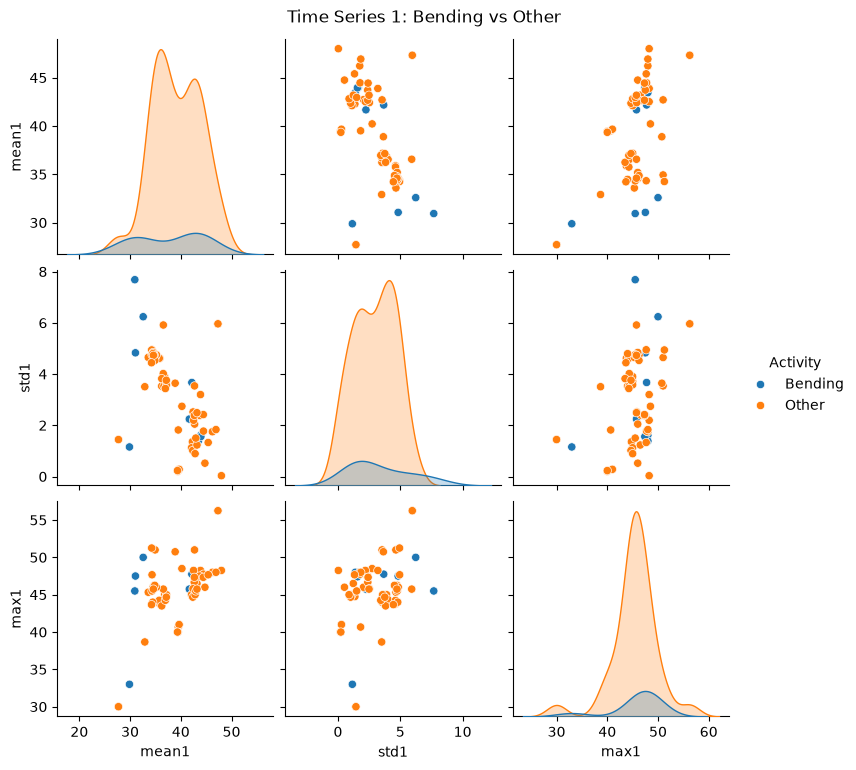

In [19]:
sns.pairplot(
    plot_df,
    vars=["mean1", "std1", "max1"],
    hue="Activity"
)

plt.suptitle("Time Series 1: Bending vs Other", y=1.02)
plt.show()

### 2(a)(ii) Splitting Each Time Series into Two Parts

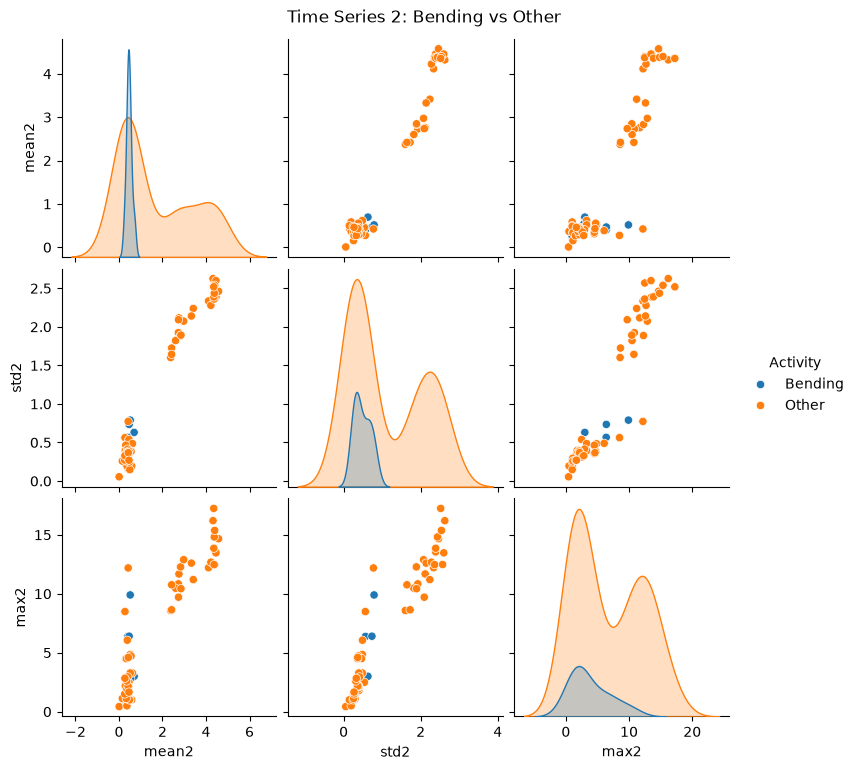

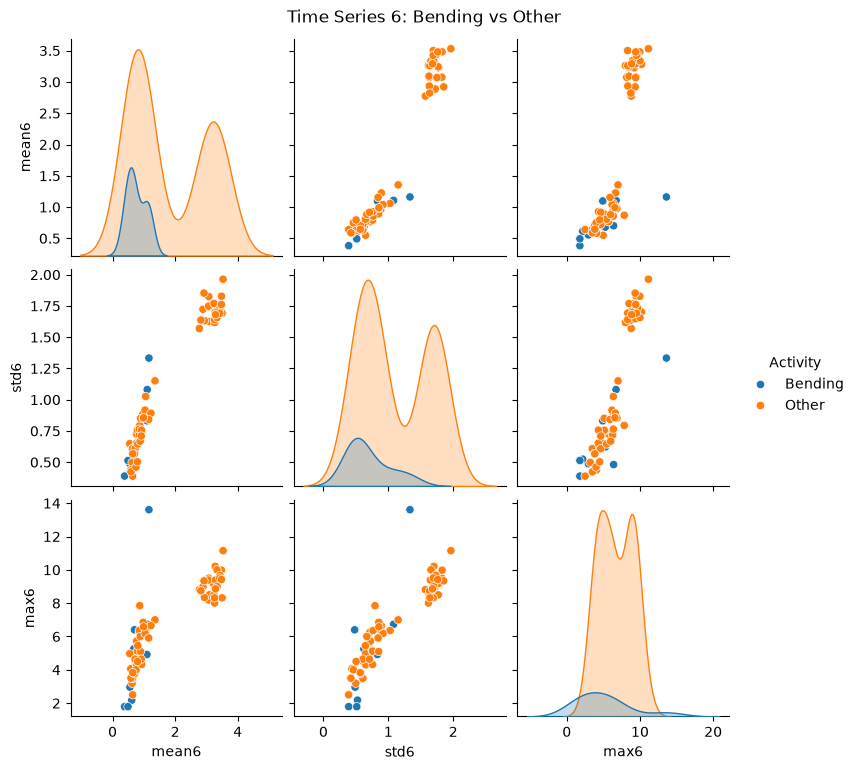

In [20]:
for ts in [2, 6]:
    sns.pairplot(
        plot_df,
        vars=[f"mean{ts}", f"std{ts}", f"max{ts}"],
        hue="Activity"
    )

    plt.suptitle(
        f"Time Series {ts}: Bending vs Other",
        y=1.02
    )

    plt.show()

In [21]:
def extract_split_features(file_path):
    df = pd.read_csv(file_path, skiprows=4, usecols=range(7))

    features = {}

    for ts in [1, 2, 6]:
        column = time_series_columns[ts - 1]
        series = df[column]

        # Split into two approximately equal parts
        parts = np.array_split(series, 2)

        for part_num, part in enumerate(parts, start=1):
            features[f"mean{ts}_part{part_num}"] = part.mean()
            features[f"std{ts}_part{part_num}"] = part.std()
            features[f"max{ts}_part{part_num}"] = part.max()

    return features

In [22]:
split_features = []

for file_path in train_files:
    features = extract_split_features(file_path)
    split_features.append(features)

split_feature_df = pd.DataFrame(split_features)

# Add the same binary labels
split_feature_df["label"] = labels

split_feature_df["Activity"] = split_feature_df["label"].map({
    1: "Bending",
    0: "Other"
})

split_feature_df.head()

,mean1_part1,std1_part1,max1_part1,mean1_part2,std1_part2,max1_part2,mean2_part1,std2_part1,max2_part1,mean2_part2,std2_part2,max2_part2,mean6_part1,std6_part1,max6_part1,mean6_part2,std6_part2,max6_part2,label,Activity
0,43.486208,1.279302,45.00,44.452042,1.767557,48.00,0.378667,0.283841,1.30,0.447583,0.235002,1.50,0.524875,0.485832,2.28,0.585750,0.486900,2.96,1,Bending
1,44.117042,1.357000,48.00,42.792875,1.056584,46.50,0.250042,0.313444,1.30,0.506125,0.260217,1.58,0.815417,0.716518,5.26,0.543875,0.472458,4.06,1,Bending
2,43.278875,3.466111,47.75,41.080750,3.530103,46.00,0.673292,0.632962,3.00,0.718792,0.626606,2.86,0.640958,0.553385,1.53,0.586083,0.490847,2.18,1,Bending
3,41.621208,3.112140,45.75,41.734917,0.594677,43.67,0.623083,0.488574,2.83,0.448875,0.272481,1.12,0.419083,0.410342,1.79,0.347500,0.362386,1.50,1,Bending
4,44.057167,1.553724,46.50,43.851833,1.553920,47.40,0.381042,0.328853,1.50,0.471458,0.341632,1.70,0.598250,0.525558,1.79,0.388333,0.477530,1.50,1,Bending


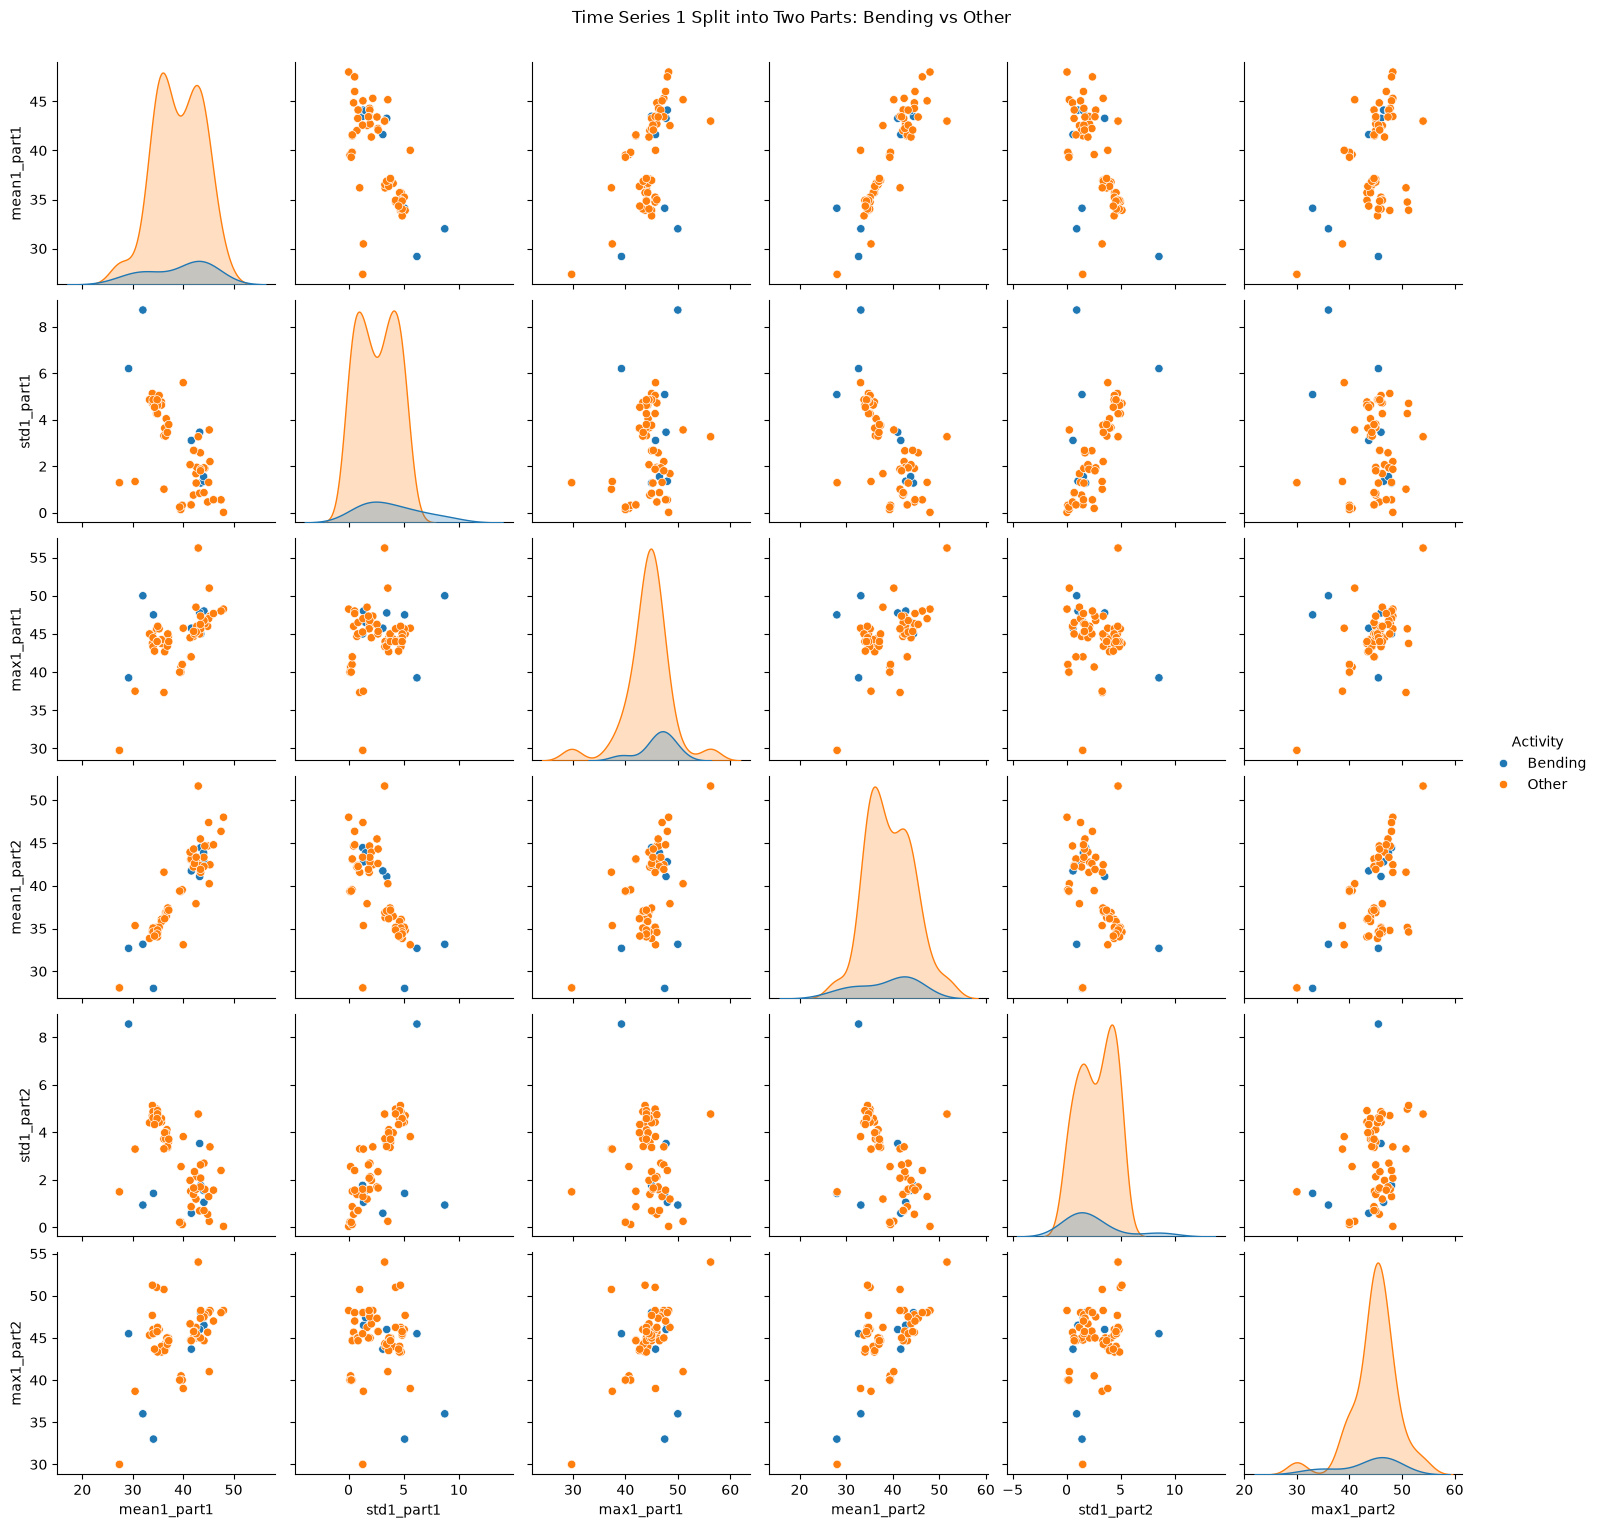

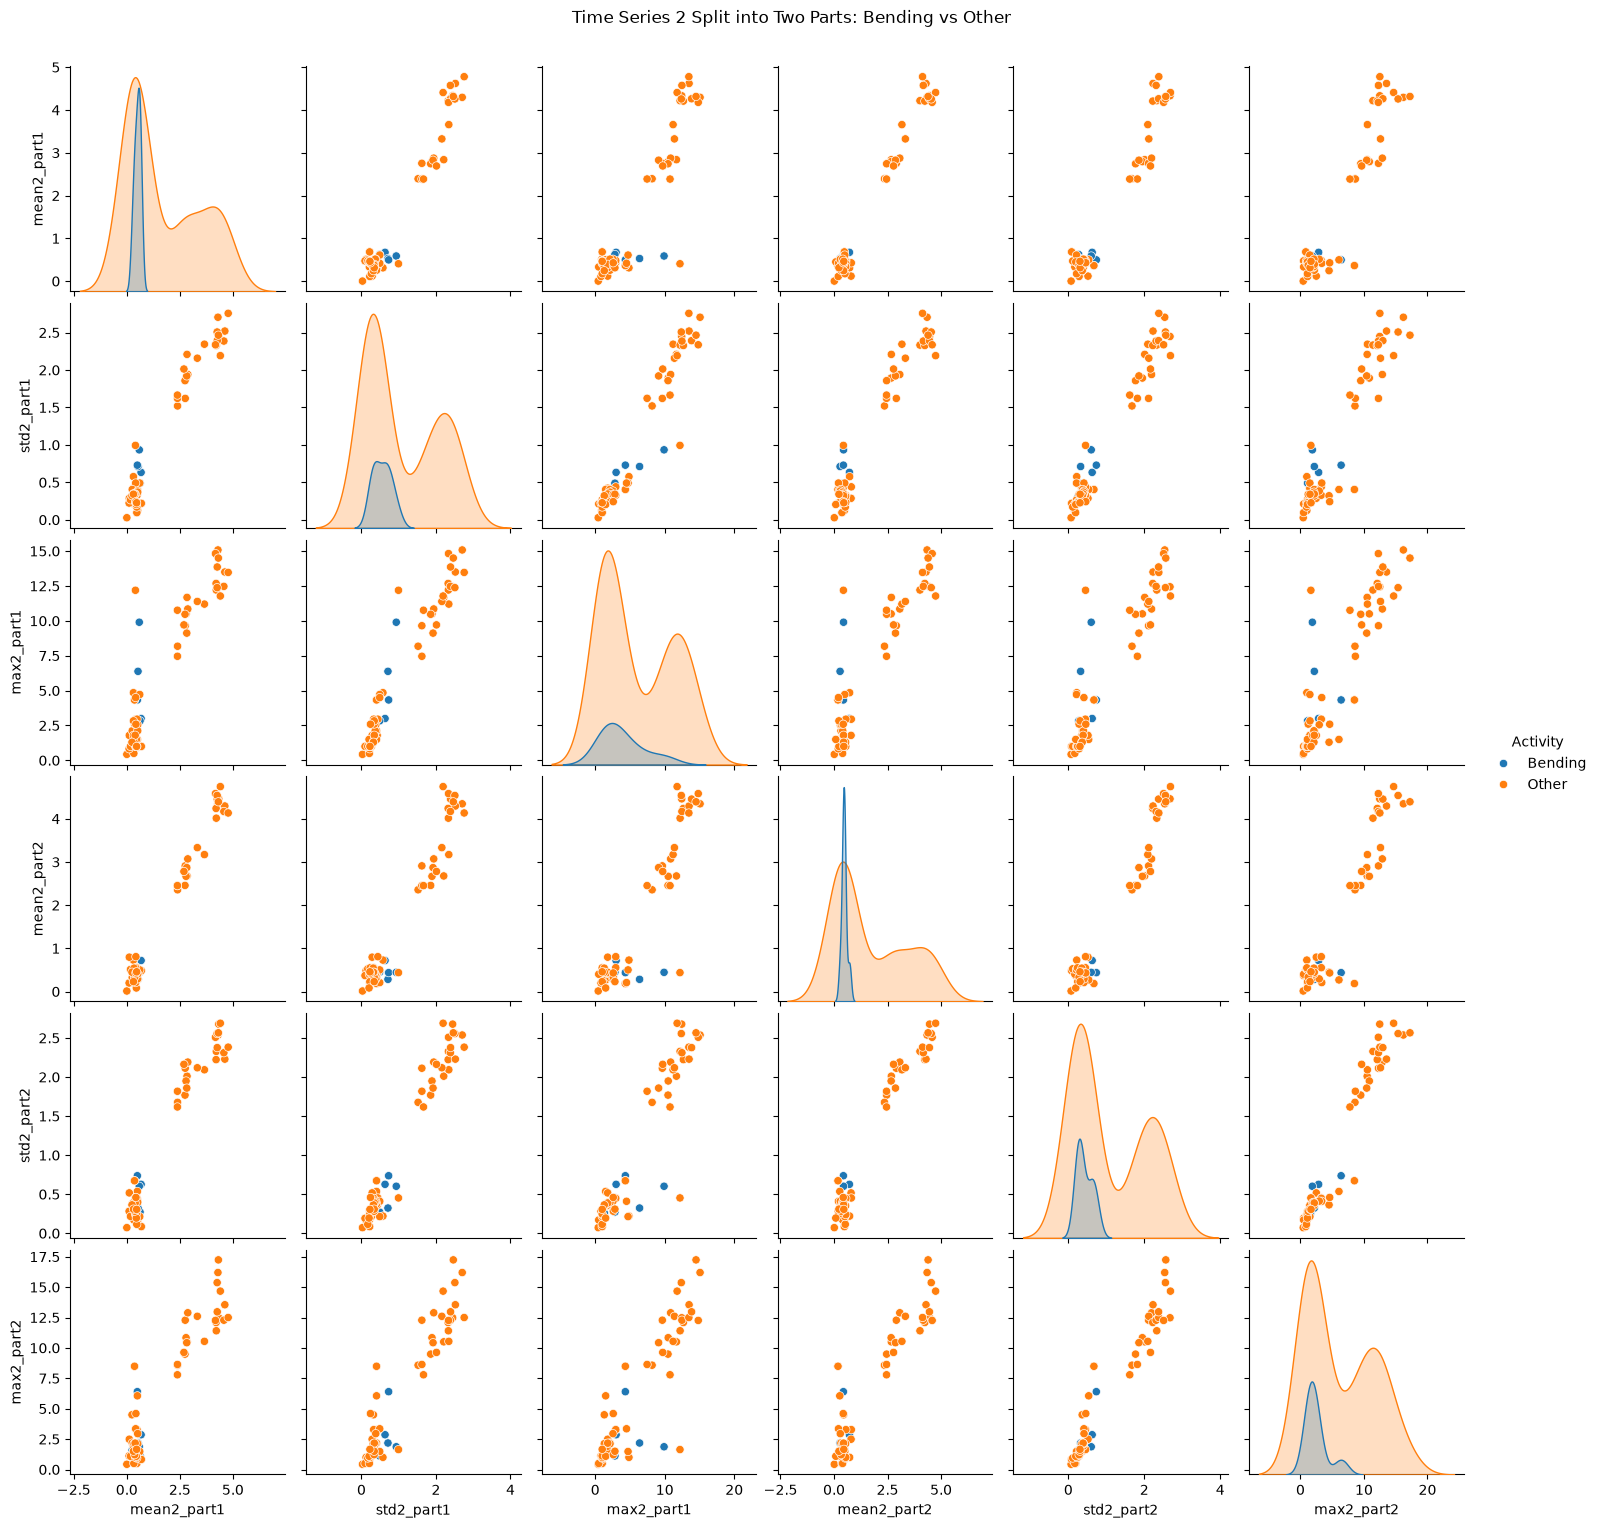

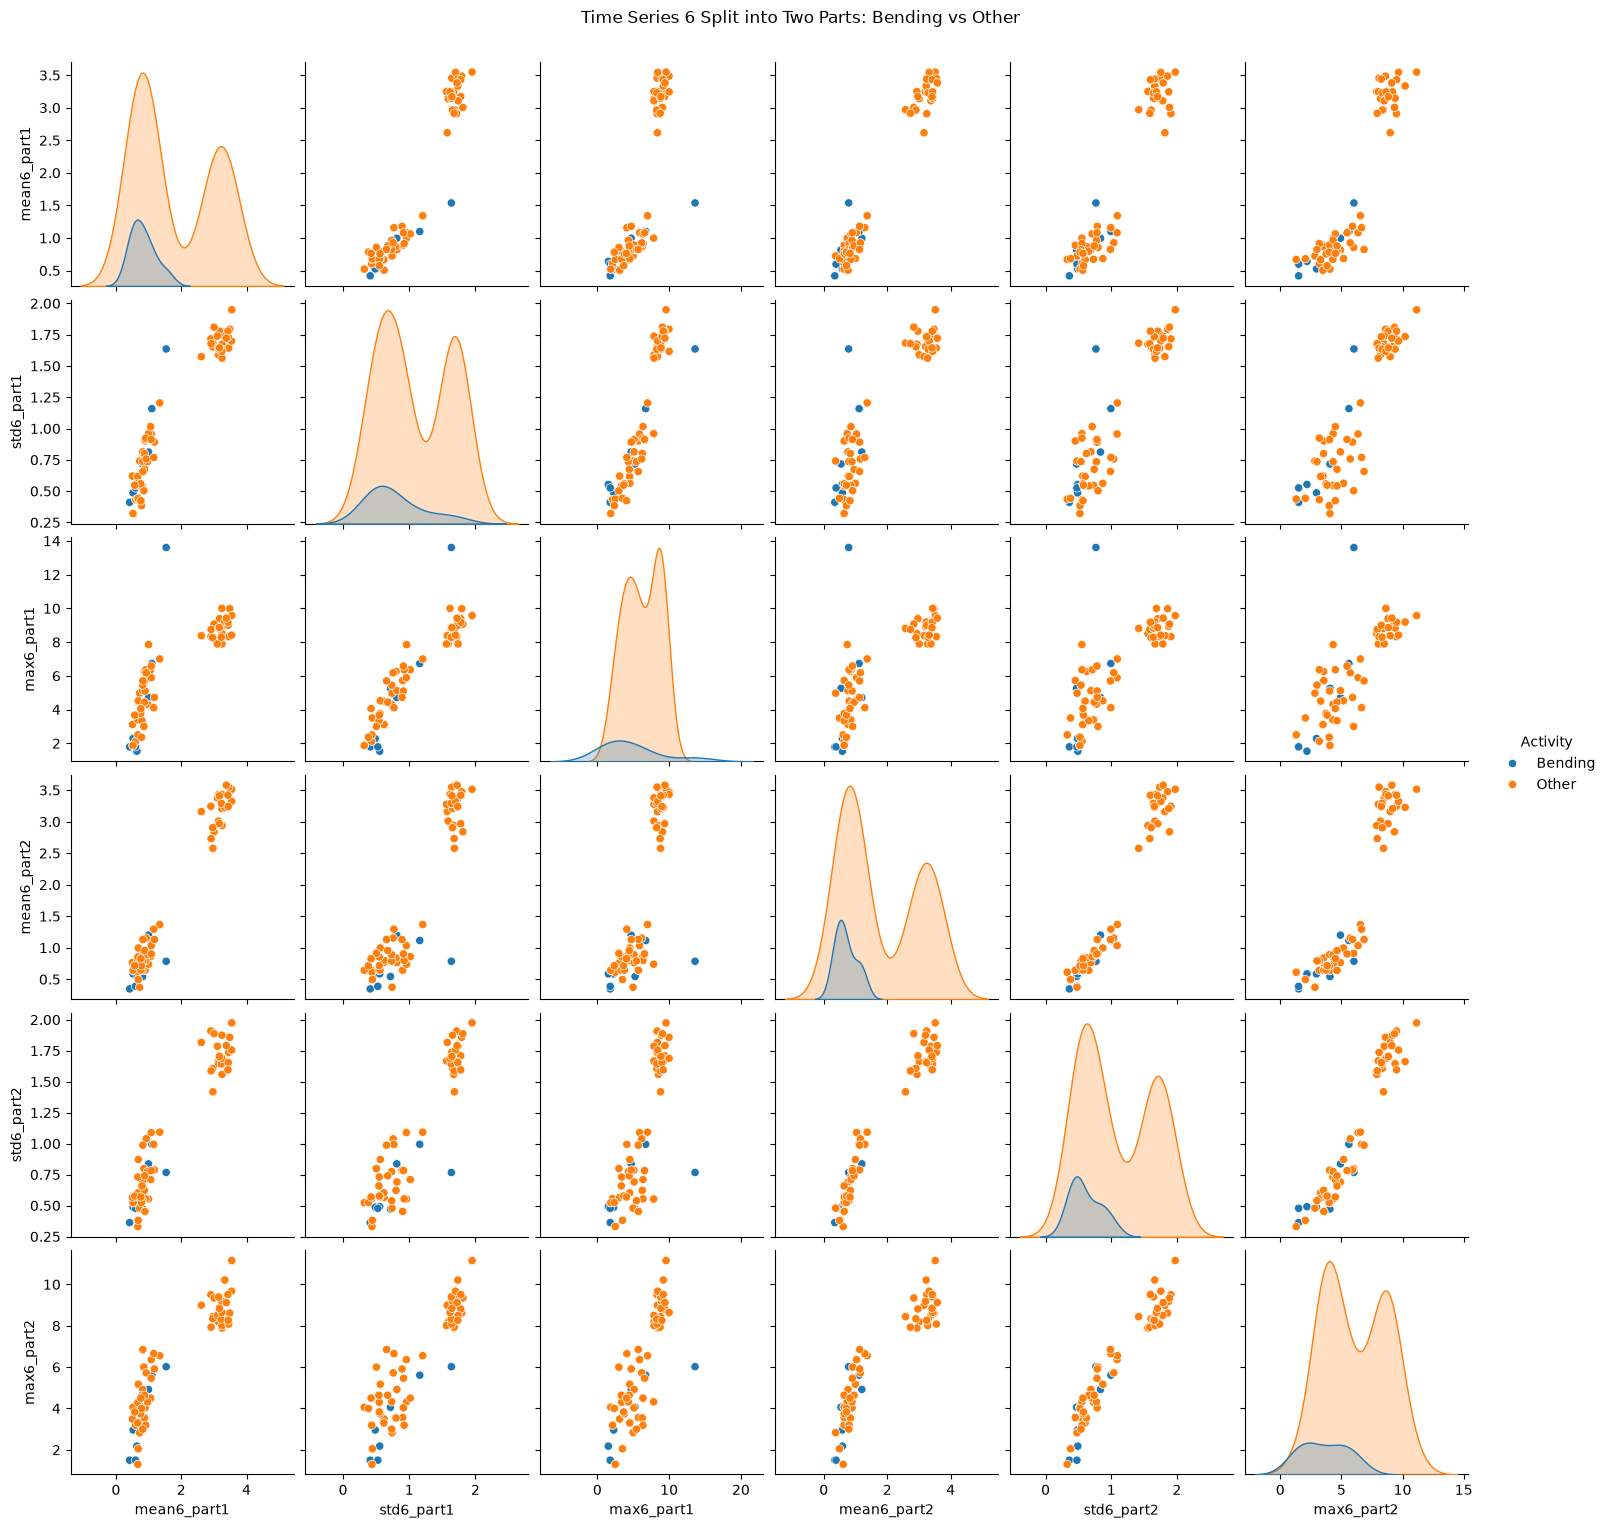

In [23]:
for ts in [1, 2, 6]:

    variables = [
        f"mean{ts}_part1",
        f"std{ts}_part1",
        f"max{ts}_part1",
        f"mean{ts}_part2",
        f"std{ts}_part2",
        f"max{ts}_part2"
    ]

    sns.pairplot(
        split_feature_df,
        vars=variables,
        hue="Activity"
    )

    plt.suptitle(
        f"Time Series {ts} Split into Two Parts: Bending vs Other",
        y=1.02
    )

    plt.show()

Each time series was split into two almost equal parts, and the features were extracted from each part. Compared with 2(a)(i), splitting the time series gives us more information. In some plots, bending and the other activities are easier to tell apart, especially for time series 2 and 6. However, there is still some overlap left between the two classes.

### (iii) Logistic Regression with Different Numbers of Time-Series Splits

In [24]:
def extract_features_l(file_path, l):
    #seperate the columns where there is on or more whitespaces and read the csv
    if "bending2/dataset4.csv" in file_path:
        df = pd.read_csv(
            file_path,
            skiprows=5,
            sep=r"\s+",
            header=None,
            names=[
                "time",
                "avg_rss12",
                "var_rss12",
                "avg_rss13",
                "var_rss13",
                "avg_rss23",
                "var_rss23"
            ]
        )

    else:
        df = pd.read_csv(
            file_path,
            skiprows=4,
            usecols=range(7)
        )

    features = []

    for column in time_series_columns:
        series = df[column]

        parts = np.array_split(series.index, l)

        for indices in parts:
            part = series.loc[indices]

            features.extend([
                part.min(),
                part.max(),
                part.mean(),
                part.median(),
                part.std(),
                part.quantile(0.25),
                part.quantile(0.75)
            ])

    return features

In [25]:
print(len(extract_features_l(train_files[0], 1)))
print(len(extract_features_l(train_files[0], 2)))
print(len(extract_features_l(train_files[0], 20)))

42
84
840


In [26]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [27]:
def build_dataset_l(l):
    X = []

    for file_path in train_files:
        features = extract_features_l(file_path, l)
        X.append(features)

    X = np.array(X)
    y = np.array(labels)

    return X, y

In [28]:
for l in [1, 2, 5, 20]:
    X, y = build_dataset_l(l)
    print(f"l = {l}: X shape = {X.shape}, y shape = {y.shape}")

l = 1: X shape = (69, 42), y shape = (69,)
l = 2: X shape = (69, 84), y shape = (69,)
l = 5: X shape = (69, 210), y shape = (69,)
l = 20: X shape = (69, 840), y shape = (69,)


In [29]:
def cross_validate_rfe(X, y, p):

    fold_scores = []

    for train_index, val_index in cv.split(X, y):

        X_train_cv = X[train_index]
        X_val_cv = X[val_index]

        y_train_cv = y[train_index]
        y_val_cv = y[val_index]

        #standardizing using training fold only
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_cv)
        X_val_scaled = scaler.transform(X_val_cv)

        # logistic regression with almost no regularization
        model = LogisticRegression(
            C=1e6,
            max_iter=5000
        )

        # Feature selection using training fold only
        selector = RFE(
            estimator=model,
            n_features_to_select=p,
            step=0.1
        )

        selector.fit(X_train_scaled, y_train_cv)

        # we keep the same features in validation data
        X_train_selected = selector.transform(X_train_scaled)
        X_val_selected = selector.transform(X_val_scaled)

        # fitting logistic regression with our selected features
        final_model = LogisticRegression(
            C=1e6,
            max_iter=5000
        )

        final_model.fit(X_train_selected, y_train_cv)

        predictions = final_model.predict(X_val_selected)

        score = accuracy_score(y_val_cv, predictions)

        fold_scores.append(score)

    return np.mean(fold_scores)

In [30]:
results = []

p_values = [1, 2, 3, 5, 10, 15, 20]

for l in range(1, 21):

    X, y = build_dataset_l(l)

    for p in p_values:

        # p needs to be less than the number of available features
        if p <= X.shape[1]:

            score = cross_validate_rfe(X, y, p)

            results.append({
                "l": l,
                "p": p,
                "cv_accuracy": score
            })

    print(f"Finished l = {l}")

Finished l = 1
Finished l = 2
Finished l = 3
Finished l = 4
Finished l = 5
Finished l = 6
Finished l = 7
Finished l = 8
Finished l = 9
Finished l = 10
Finished l = 11
Finished l = 12
Finished l = 13
Finished l = 14
Finished l = 15
Finished l = 16
Finished l = 17
Finished l = 18
Finished l = 19
Finished l = 20


In [31]:
results_df = pd.DataFrame(results)

results_df.sort_values(
    by="cv_accuracy",
    ascending=False
).head(10)

,l,p,cv_accuracy
91,14,1,0.985714
9,2,3,0.985714
69,10,20,0.985714
5,1,15,0.985714
6,1,20,0.985714
93,14,3,0.971429
131,19,15,0.971429
14,3,1,0.971429
139,20,20,0.971429
8,2,2,0.971429


In [32]:
best_l = 2
best_p = 3

# Building the entire training dataset
X, y = build_dataset_l(best_l)

# Standardizing features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# logistic regression
model = LogisticRegression(
    C=1e6,
    max_iter=5000
)

# Selecting the best 3 features
selector = RFE(
    estimator=model,
    n_features_to_select=best_p,
    step=0.1
)

selector.fit(X_scaled, y)

print("Number of features:", X.shape[1])
print("Selected feature indices:", np.where(selector.support_)[0])

Number of features: 84
Selected feature indices: [ 3 56 57]


In [33]:
feature_names_l = []

feature_types = [
    "min",
    "max",
    "mean",
    "median",
    "std",
    "1st_quart",
    "3rd_quart"
]

#creating names fro each feature
for ts in range(1, 7):
    for part in range(1, best_l + 1):
        for feature in feature_types:
            feature_names_l.append(
                f"{feature}{ts}_part{part}"
            )

#get the features that rfe selected
selected_indices = np.where(selector.support_)[0]

#converting those position into names
selected_features = [
    feature_names_l[i] for i in selected_indices
]

print("Selected features:")
for feature in selected_features:
    print(feature)

Selected features:
median1_part1
min5_part1
max5_part1


In [34]:
# keep only selected features
X_selected = selector.transform(X_scaled)

# Fit final logistic regression model
final_model = LogisticRegression(
    C=1e6,
    max_iter=5000
)

final_model.fit(X_selected, y)

print("Final model coefficients:")
print(final_model.coef_)

print("Intercept:")
print(final_model.intercept_)

Final model coefficients:
[[-7.18152321 19.10348065 13.72244371]]
Intercept:
[-24.14956762]


In [35]:
# Predictions on the training set
y_pred = final_model.predict(X_selected)

train_accuracy = accuracy_score(y, y_pred)

print("Training accuracy:", train_accuracy)
print("Training error:", 1 - train_accuracy)

Training accuracy: 1.0
Training error: 0.0


### 2(a)(iii) Binary Classification Using Logistic Regression

I tested splitting each time series into 1 to 20 approximately equal parts. Time-domain features were extracted from each part, and logistic regression with Recursive Feature Elimination (RFE) was used to classify bending versus other activities.

Stratified 5-fold cross-validation was used to find the best pair (l,p), where l is the number of parts and p is the number of features selected by RFE.

The highest cross-validation accuracy was **98.57%**. Several combinations gave the same accuracy, so I selected:
 l=2 and p=3

This combination gives the highest accuracy while keeping the number of parts and selected features relatively small.

The three features selected by RFE were:

- `median1_part1`
- `min5_part1`
- `max5_part1`

The final logistic regression model achieved **100% training accuracy**, meaning that all training instances were classified correctly.

#### Correct vs. Incorrect Cross-Validation

The correct way is to perform feature selection separately inside each training fold. We should use RFE to fit only on the training portion, and the selected features should then be used to check the validation portion.

The wrong way would be to perform feature selection on the dataset before cross-validation. This would leak information from the validation data, which would affect feature selection and cause data leakage.

Stratified 5-fold cross-validation was used because the classes are imbalanced. It helps keep the same proportion of bending and other activities in the same fold.

### 2(a)(iv) Confusion Matrix, ROC Curve, AUC, Logistic Regression Parameters, and P-values

Confusion Matrix:
[[60  0]
 [ 0  9]]


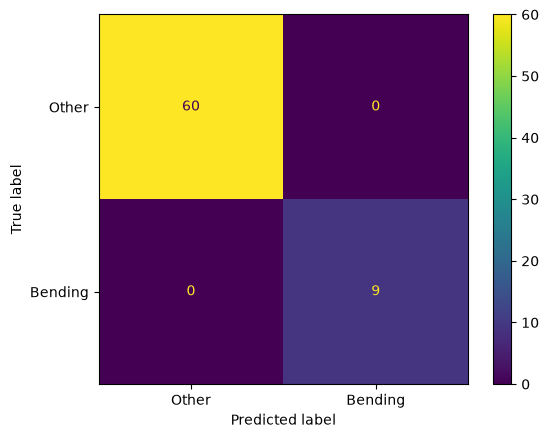

In [36]:
# predictions on training data
y_train_pred = final_model.predict(X_selected)

# confusion matrix
cm = confusion_matrix(y, y_train_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
).plot()

Training AUC: 1.0


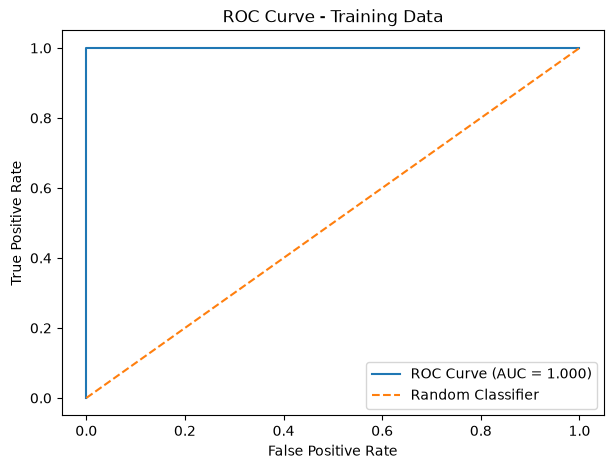

In [37]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# probability of the positive class (Bending)
y_train_prob = final_model.predict_proba(X_selected)[:, 1]

# ROC curve
fpr, tpr, thresholds = roc_curve(y, y_train_prob)

# AUC
auc_score = roc_auc_score(y, y_train_prob)

print("Training AUC:", auc_score)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Training Data")
plt.legend()
plt.show()

In [38]:
# add intercept
X_sm = sm.add_constant(X_selected)

# fit logistic regression using statsmodels
logit_model = sm.Logit(y, X_sm)
logit_result = logit_model.fit()

# create table with coefficients and p-values
results_table = pd.DataFrame({
    "Coefficient": logit_result.params,
    "P-value": logit_result.pvalues
})

results_table.index = [
    "Intercept",
    "median1_part1",
    "min5_part1",
    "max5_part1"
]

print(results_table)

         Current function value: 0.000000
         Iterations: 35
               Coefficient   P-value
Intercept       -82.995862  0.997828
median1_part1   -24.257096  0.998397
min5_part1       68.187614  0.997972
max5_part1       44.005598  0.998049


/opt/miniconda3/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/miniconda3/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/miniconda3/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/miniconda3/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/miniconda3/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callb

#### Results

The confusion matrix was:

\[
\begin{bmatrix}
60 & 0 \\
0 & 9
\end{bmatrix}
\]

Therefore, all 60 Other instances and all 9 Bending instances were classified correctly, giving a training accuracy of 100%.

The ROC curve also gave an AUC of 1, showing perfect classification on the training data.

The logistic regression parameter estimates and associated p-values obtained using `statsmodels` were:

| Parameter | Coefficient | P-value |
|---|---:|---:|
| Intercept | -82.9959 | 0.9978 |
| median1_part1 | -24.2571 | 0.9984 |
| min5_part1 | 68.1876 | 0.9980 |
| max5_part1 | 44.0056 | 0.9980 |

`statsmodels` produced PerfectSeparation and Convergence warnings because the two classes were perfectly separated in the training data, which is why the coefficient and p-value estimates are not stable and should be interpreted carefully.

### 2(a)(v) Testing the Classifier on the Test Set

In [39]:
X_test = []

for file_path in test_files:
    features = extract_features_l(file_path, 2)
    X_test.append(features)

X_test = np.array(X_test)

print("Test set shape:", X_test.shape)

Test set shape: (19, 84)


In [40]:
y_test = []

for file_path in test_files:
    if "bending1" in file_path or "bending2" in file_path:
        y_test.append(1)
    else:
        y_test.append(0)

y_test = np.array(y_test)

print("Test labels:", y_test)
print("Number of Other:", np.sum(y_test == 0))
print("Number of Bending:", np.sum(y_test == 1))

Test labels: [1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Number of Other: 15
Number of Bending: 4


In [41]:
# scaling test data using training scaler
X_test_scaled = scaler.transform(X_test)

# selecting the same features chosen from training data
X_test_selected = selector.transform(X_test_scaled)

print("Selected test shape:", X_test_selected.shape)

Selected test shape: (19, 3)


In [42]:
# predict test classes
y_test_pred = final_model.predict(X_test_selected)

# calculate accuracy and error
test_accuracy = accuracy_score(y_test, y_test_pred)
test_error = 1 - test_accuracy

print("Test Accuracy:", test_accuracy)
print("Test Error:", test_error)

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Test Accuracy: 1.0
Test Error: 0.0

Test Confusion Matrix:
[[15  0]
 [ 0  4]]


####  Results

The test accuracy was 1.00 and the test error was 0.00

The confusion matrix on the test set was:

\begin{bmatrix}
15 & 0 \\
0 & 4
\end{bmatrix}


Therefore, all instances in the test set were classified correctly.

The 5-fold cross-validation accuracy obtained in 2(a)(iii) was approximately 0.9857 (98.57%), while the test accuracy was 1.00 (100%). The two results are really close, and the test set performed slightly better than the cross-validation estimate.

### 2(a)(vi) Logistic Regression Parameter Instability

Yes, the classes appear to be very well-separated. The classifier achieved 100% accuracy on the training data, and the training confusion matrix contained 0 misclassified instances. The ROC AUC was also 1.00.

When the logistic regression model was fitted using `statsmodels`, a `PerfectSeparationWarning` and a convergence warning were produced. This shows that the bending and other classes are sufficiently separated to cause instability in estimating the logistic regression parameters.

Therefore, the logistic regression coefficients and the p-values may not be reliably estimated because of perfect separation.

### 2(a)(vii) Class Imbalance and Case-Control Sampling

In [43]:
unique, counts = np.unique(y, return_counts=True)

for label, count in zip(unique, counts):
    class_name = "Other" if label == 0 else "Bending"
    print(class_name, ":", count)

Other : 60
Bending : 9


In [44]:
# getting the indices for each class
other_idx = np.where(y == 0)[0]
bending_idx = np.where(y == 1)[0]

# randomly selecting 9 Other instances
np.random.seed(42)
sampled_other_idx = np.random.choice(
    other_idx,
    size=len(bending_idx),
    replace=False
)

# combining sampled Other and all Bending instances
case_control_idx = np.concatenate([
    sampled_other_idx,
    bending_idx
])

X_case_control = X_selected[case_control_idx]
y_case_control = y[case_control_idx]

print("Case-control X shape:", X_case_control.shape)
print("Other:", np.sum(y_case_control == 0))
print("Bending:", np.sum(y_case_control == 1))

Case-control X shape: (18, 3)
Other: 9
Bending: 9


In [45]:
case_control_model = LogisticRegression(
    C=1e6,
    max_iter=5000
)

case_control_model.fit(X_case_control, y_case_control)

print("Case-control coefficients:")
print(case_control_model.coef_)

print("\nCase-control intercept:")
print(case_control_model.intercept_)

Case-control coefficients:
[[-9.24171801 14.81789521 17.77085535]]

Case-control intercept:
[-21.8839751]


In [46]:
# original and sampled proportions of Bending
pi_original = np.mean(y)
pi_sample = np.mean(y_case_control)

# intercept correction
intercept_adjustment = np.log(
    (pi_original / (1 - pi_original)) /
    (pi_sample / (1 - pi_sample))
)

adjusted_intercept = (
    case_control_model.intercept_[0]
    + intercept_adjustment
)

print("Original Bending proportion:", pi_original)
print("Case-control Bending proportion:", pi_sample)
print("Intercept adjustment:", intercept_adjustment)
print("Original case-control intercept:", case_control_model.intercept_[0])
print("Adjusted intercept:", adjusted_intercept)

Original Bending proportion: 0.13043478260869565
Case-control Bending proportion: 0.5
Intercept adjustment: -1.8971199848858813
Original case-control intercept: -21.883975103154228
Adjusted intercept: -23.78109508804011


Adjusted Case-Control Confusion Matrix:
[[60  0]
 [ 0  9]]


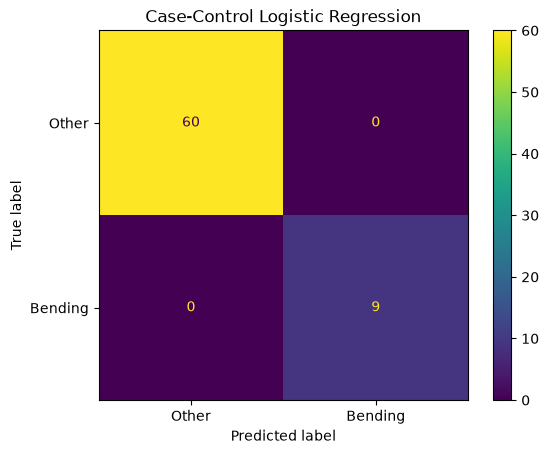

In [47]:
# calculating probabilities using adjusted intercept
log_odds = (
    adjusted_intercept
    + np.dot(X_selected, case_control_model.coef_[0])
)

y_prob_adjusted = 1 / (1 + np.exp(-log_odds))

# converting probabilities to predictions
y_pred_adjusted = (y_prob_adjusted >= 0.5).astype(int)

# confusion matrix
cm_adjusted = confusion_matrix(y, y_pred_adjusted)

print("Adjusted Case-Control Confusion Matrix:")
print(cm_adjusted)

ConfusionMatrixDisplay(
    confusion_matrix=cm_adjusted,
    display_labels=["Other", "Bending"]
).plot()

plt.title("Case-Control Logistic Regression")
plt.show()

Adjusted Case-Control AUC: 1.0


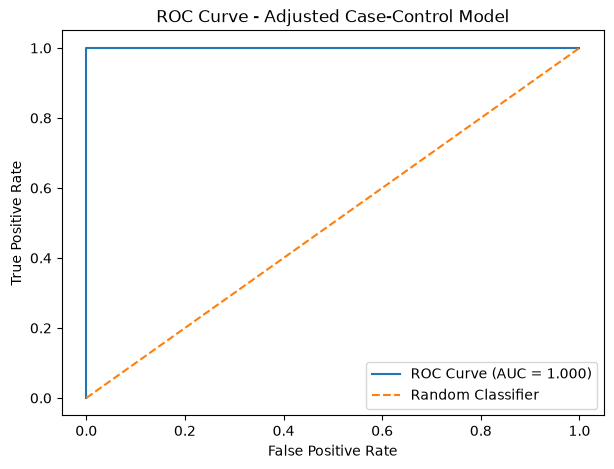

In [48]:
# ROC and AUC
fpr, tpr, thresholds = roc_curve(y, y_prob_adjusted)
auc_adjusted = roc_auc_score(y, y_prob_adjusted)

print("Adjusted Case-Control AUC:", auc_adjusted)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {auc_adjusted:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Adjusted Case-Control Model")
plt.legend()

plt.show()

#### Case-Control Sampling Results

The original training data is imbalanced, containing 60 Other instances and only 9 Bending instances. That is why we needed case-control sampling to create a balanced sample containing 9 Other and 9 Bending instances.

A logistic regression model was fitted to the balanced sample. Since case-control sampling changes the proportion of the classes, the intercept was adjusted to account for the original class distribution. The original case-control intercept was -21.8840, and after adjustment the intercept was -23.7811.

The adjusted case-control model achieved an AUC of 1

The ROC curve shows perfect separation between the Bending and Other classes. The model therefore maintains strong classification performance even after accounting for the class imbalance.

### 2(b)(i) Binary Classification Using L1-Penalized Logistic Regression

In [49]:

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [50]:
def cross_validate_l1(X, y, C):
    fold_scores = []

    for train_index, val_index in cv.split(X, y):
        X_train_cv = X[train_index]
        X_val_cv = X[val_index]

        y_train_cv = y[train_index]
        y_val_cv = y[val_index]

        # scaling within the fold
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_cv)
        X_val_scaled = scaler.transform(X_val_cv)

        # L1 logistic regression
        model = LogisticRegression(
            l1_ratio=1,
            C=C,
            solver="liblinear",
            max_iter=5000
        )

        model.fit(X_train_scaled, y_train_cv)

        predictions = model.predict(X_val_scaled)

        score = accuracy_score(y_val_cv, predictions)
        fold_scores.append(score)

    return np.mean(fold_scores)

In [51]:
X, y = build_dataset_l(1)

test_score = cross_validate_l1(
    X,
    y,
    C=1
)

print("CV Accuracy:", test_score)


CV Accuracy: 0.9857142857142858


In [52]:
l1_results = []

for l in range(1, 21):
    X, y = build_dataset_l(l)

    for C in C_values:
        score = cross_validate_l1(X, y, C)

        l1_results.append({
            "l": l,
            "C": C,
            "cv_accuracy": score
        })

    print(f"Finished l = {l}")

Finished l = 1
Finished l = 2
Finished l = 3
Finished l = 4
Finished l = 5
Finished l = 6
Finished l = 7
Finished l = 8
Finished l = 9
Finished l = 10
Finished l = 11
Finished l = 12
Finished l = 13
Finished l = 14
Finished l = 15
Finished l = 16
Finished l = 17
Finished l = 18
Finished l = 19
Finished l = 20


In [53]:
l1_results_df = pd.DataFrame(l1_results)

l1_results_df.sort_values(
    by="cv_accuracy",
    ascending=False
).head(10)

,l,C,cv_accuracy
3,1,1.0,0.985714
69,12,1.0,0.985714
70,12,10.0,0.985714
105,18,1.0,0.985714
106,18,10.0,0.985714
119,20,100.0,0.971429
22,4,10.0,0.971429
59,10,100.0,0.971429
52,9,10.0,0.971429
107,18,100.0,0.971429


In [54]:
best_l = 1
best_C = 1

# building training data
X_l1, y_l1 = build_dataset_l(best_l)

# scaling training data
l1_scaler = StandardScaler()
X_l1_scaled = l1_scaler.fit_transform(X_l1)

# fit final L1 logistic regression
final_l1_model = LogisticRegression(
    l1_ratio=1,
    C=best_C,
    solver="liblinear",
    max_iter=5000
)

final_l1_model.fit(X_l1_scaled, y_l1)

# training accuracy
l1_train_pred = final_l1_model.predict(X_l1_scaled)

print(
    "Training Accuracy:",
    accuracy_score(y_l1, l1_train_pred)
)

print(
    "Number of non-zero coefficients:",
    np.sum(final_l1_model.coef_[0] != 0)
)

Training Accuracy: 1.0
Number of non-zero coefficients: 7


In [55]:
selected_l1_features = []

for name, coef in zip(feature_names, final_l1_model.coef_[0]):
    if coef != 0:
        selected_l1_features.append((name, coef))

selected_l1_df = pd.DataFrame(
    selected_l1_features,
    columns=["Feature", "Coefficient"]
)

selected_l1_df

,Feature,Coefficient
0,3rd_quart1,-0.568189
1,1st_quart3,-0.020496
2,1st_quart4,-0.124037
3,min5,1.101025
4,max5,1.738791
5,median6,-0.190138
6,1st_quart6,-0.603042


### 2(b)(ii) Comparison of L1-Penalized Logistic Regression and Variable Selection

Both methods achieved approximately the same best cross-validation accuracy of 98.57%, so neither method performed better in terms of cross-validation accuracy.

However, L1-penalized logistic regression was easier to implement because feature selection is performed automatically by shrinking some coefficients to zero. The variable-selection approach requires a separate feature-selection procedure such as RFE in addition to fitting the logistic regression model.

### 2(c)(i) L1-Penalized Multinomial Regression for Multi-Class Classification

In [56]:
y_train_multi = []

for file_path in train_files:
    activity = file_path.split("/")[-2]
    y_train_multi.append(activity)

y_train_multi = np.array(y_train_multi)

print("Classes:", np.unique(y_train_multi))
print("Number of training instances:", len(y_train_multi))


Classes: ['bending1' 'bending2' 'cycling' 'lying' 'sitting' 'standing' 'walking']
Number of training instances: 69


In [57]:
cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

def cross_validate_multiclass_l1(X, y, C):
    fold_scores = []

    for train_index, val_index in cv_multi.split(X, y):
        X_train_cv = X[train_index]
        X_val_cv = X[val_index]

        y_train_cv = y[train_index]
        y_val_cv = y[val_index]

        # scale within each fold
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_cv)
        X_val_scaled = scaler.transform(X_val_cv)

        # multiclass L1 logistic regression
        model = LogisticRegression(
            l1_ratio=1,
            C=C,
            solver="saga",
            max_iter=10000
        )

        model.fit(X_train_scaled, y_train_cv)

        predictions = model.predict(X_val_scaled)

        score = accuracy_score(y_val_cv, predictions)
        fold_scores.append(score)

    return np.mean(fold_scores)

In [58]:
X_multi, _ = build_dataset_l(1)

test_score = cross_validate_multiclass_l1(
    X_multi,
    y_train_multi,
    C=1
)

print("Multiclass CV Accuracy:", test_score)

Multiclass CV Accuracy: 0.8848039215686274


In [59]:
multi_results = []

for l in range(1, 21):
    X_multi, _ = build_dataset_l(l)

    for C in C_values:
        score = cross_validate_multiclass_l1(
            X_multi,
            y_train_multi,
            C
        )

        multi_results.append({
            "l": l,
            "C": C,
            "cv_accuracy": score
        })

    print(f"Finished l = {l}")

Finished l = 1
Finished l = 2
Finished l = 3
Finished l = 4
Finished l = 5
Finished l = 6
Finished l = 7
Finished l = 8
Finished l = 9
Finished l = 10
Finished l = 11
Finished l = 12
Finished l = 13
Finished l = 14
Finished l = 15
Finished l = 16
Finished l = 17
Finished l = 18
Finished l = 19
Finished l = 20


In [60]:
multi_results_df = pd.DataFrame(multi_results)

multi_results_df.sort_values(
    by="cv_accuracy",
    ascending=False
).head(10)

,l,C,cv_accuracy
4,1,10.0,0.914216
5,1,100.0,0.898693
11,2,100.0,0.898693
23,4,100.0,0.897876
10,2,10.0,0.884804
3,1,1.0,0.884804
22,4,10.0,0.883987
9,2,1.0,0.857026
29,5,100.0,0.854575
107,18,100.0,0.853758


In [61]:
best_l_multi = 1
best_C_multi = 10

X_train_multi, _ = build_dataset_l(best_l_multi)

multi_scaler = StandardScaler()
X_train_multi_scaled = multi_scaler.fit_transform(X_train_multi)

# final multiclass logistic regression
final_multi_model = LogisticRegression(
    l1_ratio=1,
    C=best_C_multi,
    solver="saga",
    max_iter=10000
)

final_multi_model.fit(
    X_train_multi_scaled,
    y_train_multi
)

print("Training Accuracy:",
      accuracy_score(
          y_train_multi,
          final_multi_model.predict(X_train_multi_scaled)
      ))

Training Accuracy: 1.0


In [62]:
y_test_multi = []

for file_path in test_files:
    activity = file_path.split("/")[-2]
    y_test_multi.append(activity)

y_test_multi = np.array(y_test_multi)

print("Test classes:", np.unique(y_test_multi))
print("Number of test instances:", len(y_test_multi))

Test classes: ['bending1' 'bending2' 'cycling' 'lying' 'sitting' 'standing' 'walking']
Number of test instances: 19


In [63]:
X_test_multi = []

for file_path in test_files:
    features = extract_features_l(file_path, best_l_multi)
    X_test_multi.append(features)

X_test_multi = np.array(X_test_multi)

# using training scaler 
X_test_multi_scaled = multi_scaler.transform(X_test_multi)

print("Test shape:", X_test_multi_scaled.shape)

Test shape: (19, 42)


In [64]:
y_test_multi_pred = final_multi_model.predict(
    X_test_multi_scaled
)

multi_test_accuracy = accuracy_score(
    y_test_multi,
    y_test_multi_pred
)

multi_test_error = 1 - multi_test_accuracy

print("Test Accuracy:", multi_test_accuracy)
print("Test Error:", multi_test_error)

Test Accuracy: 0.9473684210526315
Test Error: 0.052631578947368474


Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 0 3 0]
 [0 0 0 0 0 0 3]]


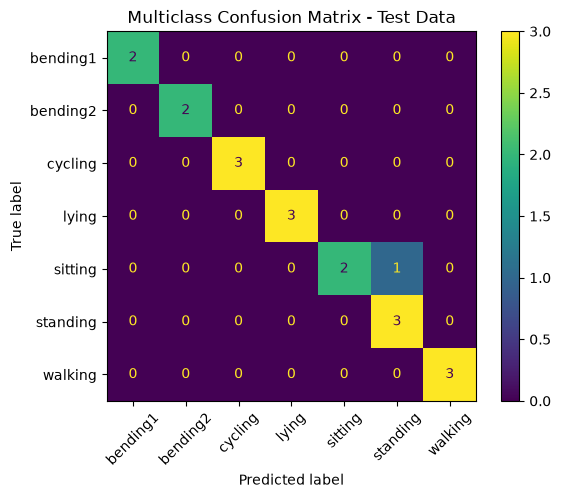

In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_multi = confusion_matrix(
    y_test_multi,
    y_test_multi_pred,
    labels=final_multi_model.classes_
)

print("Confusion Matrix:")
print(cm_multi)

ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=final_multi_model.classes_
).plot(
    xticks_rotation=45
)

plt.title("Multiclass Confusion Matrix - Test Data")
plt.show()

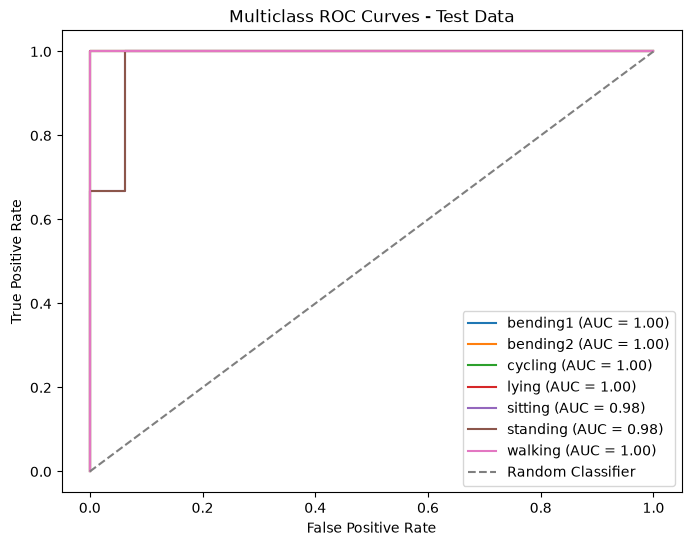

In [66]:

# predicted probabilities
y_test_multi_prob = final_multi_model.predict_proba(
    X_test_multi_scaled
)

classes = final_multi_model.classes_

# convert labels to one-vs-rest binary format
y_test_bin = label_binarize(
    y_test_multi,
    classes=classes
)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(classes):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_test_multi_prob[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.2f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves - Test Data")
plt.legend()
plt.show()

#### Multiclass Classification Results

The best L1-penalized multinomial logistic regression model used l = 1 and C =10

The test accuracy was approximately 94.74%, giving a test error of 5.25%

The multiclass confusion matrix shows that 18 of the 19 test instances were classified correctly. The only misclassification was one `sitting` instance that was predicted as `standing`.

Multiclass ROC analysis used a one-vs-rest approach, where each activity was treated as the positive class against all remaining activities. The AUC values were 1.00 for bending1, bending2, cycling, lying, and walking, and approximately 0.98 for sitting and standing.

### 2(c)(ii) Multi-Class Classification Using Naïve Bayes

In [67]:
from sklearn.naive_bayes import GaussianNB

# Gaussian Naive Bayes
gaussian_nb = GaussianNB()

gaussian_nb.fit(
    X_train_multi_scaled,
    y_train_multi
)

# predictions on test set
gaussian_pred = gaussian_nb.predict(
    X_test_multi_scaled
)

# accuracy and error
gaussian_accuracy = accuracy_score(
    y_test_multi,
    gaussian_pred
)

gaussian_error = 1 - gaussian_accuracy

print("Gaussian NB Test Accuracy:", gaussian_accuracy)
print("Gaussian NB Test Error:", gaussian_error)

Gaussian NB Test Accuracy: 0.8947368421052632
Gaussian NB Test Error: 0.10526315789473684


In [68]:
# Multinomial Naive Bayes
multinomial_nb = MultinomialNB()

multinomial_nb.fit(
    X_train_multi,
    y_train_multi
)

# predictions on test set
multinomial_pred = multinomial_nb.predict(
    X_test_multi
)

# accuracy and error
multinomial_accuracy = accuracy_score(
    y_test_multi,
    multinomial_pred
)

multinomial_error = 1 - multinomial_accuracy

print("Multinomial NB Test Accuracy:", multinomial_accuracy)
print("Multinomial NB Test Error:", multinomial_error)

Multinomial NB Test Accuracy: 0.8947368421052632
Multinomial NB Test Error: 0.10526315789473684


#### Comparison

Gaussian Naïve Bayes and Multinomial Naïve Bayes produced the same performance on the test set. Both models achieved a test accuracy of approximately 89.47% and a test error of approximately 10.53%.

Therefore, neither Naïve Bayes method performed better than the other on this dataset.

### 2(c)(iii) Comparison of Multi-Class Classification Methods

The L1-penalized multinomial logistic regression model performed better for multi-class classification in this problem. It achieved a test accuracy of approximately 94.74% and a test error of 5.26%.

While, both Gaussian Naïve Bayes and Multinomial Naïve Bayes achieved a test accuracy of approximately 89.47% and a test error of 10.53%.

Therefore, L1-penalized multinomial logistic regression is the better method for this dataset because it achieved the lowest test error.


### 3. ISLR 4.8.3

For QDA with one predictor, observations in class \(k\) follow a normal distribution:

\[
X \sim N(\mu_k,\sigma_k^2).
\]

The density function for class \(k\) is

\[
f_k(x)=\frac{1}{\sqrt{2\pi\sigma_k^2}}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
\]

The Bayes classifier assigns an observation \(X=x\) to the class for which \(\pi_k f_k(x)\) is largest. Taking the logarithm gives the discriminant function

\[
\delta_k(x)
=\log(\pi_k)
-\frac{1}{2}\log(2\pi\sigma_k^2)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
\]

Expanding the squared term,

\[
\delta_k(x)
=-\frac{1}{2\sigma_k^2}x^2
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac{1}{2}\log(2\pi\sigma_k^2)
+\log(\pi_k).
\]

Therefore, the discriminant function has the form

\[
\delta_k(x)=A_kx^2+B_kx+C_k.
\]

To find the decision boundary between classes \(k\) and \(l\), we set

\[
\delta_k(x)=\delta_l(x).
\]

Subtracting the two discriminant functions gives

\[
\left(\frac{1}{2\sigma_l^2}-\frac{1}{2\sigma_k^2}\right)x^2
+
\left(\frac{\mu_k}{\sigma_k^2}-\frac{\mu_l}{\sigma_l^2}\right)x
+C=0,
\]

where \(C\) is the terms that are independent of \(x\).

Since QDA allows each class to have its own variance, when \(\sigma_k^2 \neq \sigma_l^2\), the coefficient of \(x^2\) is nonzero. The quadratic terms do not cancel, and the decision boundary is determined by a quadratic equation.

LDA assumes equal variances across classes, causing the quadratic terms to cancel and resulting in a linear discriminant.

**Hence, the Bayes classifier under QDA is generally quadratic rather than linear, except in special cases where the class variances are equal.**


### 4. ISLR 4.8.7

Let \(Y\) be a company that issues a dividend and \(N\) represent that it does not.

We are given

\[
\mu_Y=10, \qquad \mu_N=0, \qquad \sigma^2=36,
\]

and

\[
P(Y)=0.8, \qquad P(N)=0.2.
\]

Using the normal density function,

\[
f(x)=\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),
\]

we get

\[
f_Y(4)=
\frac{1}{\sqrt{2\pi(36)}}
\exp\left(-\frac{(4-10)^2}{2(36)}\right)
\]

and

\[
f_N(4)=
\frac{1}{\sqrt{2\pi(36)}}
\exp\left(-\frac{(4-0)^2}{2(36)}\right).
\]

Using Bayes' theorem,

\[
P(Y\mid X=4)
=
\frac{P(Y)f_Y(4)}
{P(Y)f_Y(4)+P(N)f_N(4)}.
\]

Therefore,

\[
P(Y\mid X=4)
=
\frac{0.8f_Y(4)}
{0.8f_Y(4)+0.2f_N(4)}
\approx 0.752.
\]

Thus, the probability that the company will issue a dividend this year given that its profit was \(4\%\) last year is approximately

\[
\boxed{75.2\%}.
\]